# Ensambles de modelos y ajuste de hiperparámetros
## Data Mining - Doctorado UDP 2026
**Dr. Bastián González-Bustamante, Profesor Asociado** \
Octubre 2026

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Doctorado-UDP/data-mining-2026/blob/main/code/3_ensambles_y_ajuste.ipynb)

**Sesión 10 · jueves 29 de octubre de 2026 · Parte 2: demostración.**

En S8 comparamos modelos individuales y en S9 aprendimos a estimar su desempeño sin fugas. Este notebook combina modelos (**ensambles**) y ajusta sus hiperparámetros dentro de la validación cruzada. Usamos el mismo problema de S8 y S9 (5 clases de valor de la vivienda en California, macro F1) y, al final, una serie de tiempo de calidad del aire en Pekín para validar con **ventanas temporales**. Cada sección corresponde a una sección de la presentación:

| N.º | Sección | Presentación |
|---|---|---|
| 1 | Datos y partición (igual que S8 y S9) | Repaso S8–S9 |
| 2 | Por qué funcionan los ensambles | Ensamblaje de modelos: diversidad, sesgo y varianza |
| 3 | Votación dura y blanda | Métodos básicos: votación |
| 4 | Bagging y random forest | Bagging |
| 5 | Boosting: AdaBoost, gradient boosting y XGBoost | Boosting |
| 6 | Stacking (bien y mal hecho) | Stacking |
| 7 | Ajuste de hiperparámetros: grilla, búsqueda aleatoria y Optuna | Ajuste de hiperparámetros |
| 8 | Datos temporales: ventanas expansivas y móviles | Ventanas móviles |
| 9 | Ejercicios | No aplica |

**Cómo usarlo.**
- Las celdas precedidas por **▶ En vivo** se ejecutan durante la clase. El resto queda para la revisión autónoma.
- Todo el notebook corre de principio a fin en la CPU de un computador portátil en unos 5 minutos. Para lograrlo, las búsquedas de hiperparámetros usan presupuestos pequeños (16 a 25 configuraciones con 3 pliegues); cada sección lo indica. La sección más lenta es la 7 (2 a 3 minutos). La sección 8 descarga unos 8 MB del repositorio UCI.
- Las versiones de las librerías están fijadas en el archivo `requirements.txt` del repositorio del curso. Esta sesión agrega `optuna`, que Colab no trae preinstalado: la celda "Entorno" lo instala.
- `random_state=86` en todos los pasos aleatorios, para que los resultados sean reproducibles.
- Reglas de esta sesión: **el conjunto de prueba no se toca**; los hiperparámetros se eligen con validación cruzada **dentro de entrenamiento**; el conjunto de validación sirve para comparar modelos ya ajustados.

### Entorno: local o Google Colab

Este notebook corre en su computador y en Google Colab. La primera celda de código detecta dónde se ejecuta:
- **En Google Colab** instala solo los paquetes que falten (en esta sesión, `optuna`), sin actualizar los preinstalados, así que no hace falta reiniciar la sesión. Los datos se descargan de fuentes públicas. Para conservar sus cambios, use "Archivo → Guardar una copia en Drive".
- **En su computador** no instala nada: cree antes un entorno virtual con `pip install -r requirements.txt`.

Luego muestra las versiones instaladas y verifica que estén en el rango soportado: Python ≥ 3.11, scikit-learn ≥ 1.6, pandas ≥ 2.2 y NumPy ≥ 2.0. Con versiones distintas de las de `requirements.txt`, algunos resultados pueden cambiar levemente.

En Colab, `%pip` puede mostrar "Note: you may need to restart the kernel to use updated packages". No hace falta reiniciar: `optuna` es un paquete nuevo, no una actualización. Los resultados de `HistGradientBoosting` y XGBoost pueden cambiar en milésimas respecto de los comentados en el texto, porque Colab usa otra versión de scikit-learn y 2 hilos de cómputo en vez de 8; las conclusiones no cambian.

In [1]:
## Entorno: detectar Google Colab, instalar solo lo que falte y verificar las versiones
import re
import sys
from importlib import invalidate_caches
from importlib.metadata import version
from importlib.util import find_spec

## Paquetes que usa este notebook: {módulo: (nombre en pip, versión mínima soportada)}
PAQUETES = {
    "sklearn": ("scikit-learn", "1.6"),
    "pandas": ("pandas", "2.2"),
    "numpy": ("numpy", "2.0"),
    "matplotlib": ("matplotlib", "3.9"),
    "xgboost": ("xgboost", "2.1"),
    "optuna": ("optuna", "4.0"),
}

EN_COLAB = "google.colab" in sys.modules
faltan = [pip for modulo, (pip, _) in PAQUETES.items() if find_spec(modulo) is None]
if faltan and EN_COLAB:
    ## En Colab se instalan solo los paquetes que faltan; los preinstalados no se actualizan
    get_ipython().run_line_magic("pip", "install -q " + " ".join(faltan))
    invalidate_caches()
    faltan = []
## En su computador no se instala nada: el entorno virtual se crea con requirements.txt
assert not faltan, f"Faltan paquetes: {', '.join(faltan)}. Instálelos con pip install -r requirements.txt."


def version_al_menos(paquete, minima):
    ## Compara los dos primeros números de la versión instalada con la mínima (p. ej., "1.6.1" >= "1.6")
    actual = tuple(int(n) for n in re.findall(r"\d+", version(paquete))[:2])
    return actual >= tuple(int(n) for n in minima.split("."))


print(f"Python {sys.version.split()[0]} | "
      + " | ".join(f"{pip} {version(pip)}" for pip, _ in PAQUETES.values())
      + (" | Google Colab" if EN_COLAB else " | computador local"))
assert sys.version_info >= (3, 11), "Este notebook requiere Python 3.11 o superior."
antiguos = [f"{pip} {version(pip)} (mínimo {minima})" for pip, minima in PAQUETES.values()
            if not version_al_menos(pip, minima)]
assert not antiguos, f"Versiones no soportadas: {'; '.join(antiguos)}. Actualice esos paquetes en su entorno."

Python 3.12.7 | scikit-learn 1.9.1 | pandas 3.0.6 | numpy 2.5.4 | matplotlib 3.11.2 | xgboost 3.4.1 | optuna 5.0.0 | computador local


In [2]:
## Importar librerías necesarias
import io
import os
import time
import zipfile
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import binom, loguniform, randint, uniform
from threadpoolctl import threadpool_limits

import sklearn
import xgboost as xgb
import optuna
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import (
    train_test_split, cross_val_predict, cross_validate, GridSearchCV, RandomizedSearchCV,
    StratifiedKFold, KFold, TimeSeriesSplit
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.calibration import CalibratedClassifierCV
from sklearn.ensemble import (
    VotingClassifier, BaggingClassifier, RandomForestClassifier, AdaBoostClassifier,
    HistGradientBoostingClassifier, StackingClassifier, RandomForestRegressor
)
from sklearn.metrics import f1_score, accuracy_score, mean_absolute_error

## Versiones (en su computador, las de requirements.txt; en Colab, las preinstaladas)
print(f"pandas {pd.__version__} | numpy {np.__version__} | scikit-learn {sklearn.__version__} | "
      f"xgboost {xgb.__version__} | optuna {optuna.__version__}")

pandas 3.0.6 | numpy 2.5.4 | scikit-learn 1.9.1 | xgboost 3.4.1 | optuna 5.0.0


**Hilos de cómputo.** Varios modelos de esta sesión (`HistGradientBoosting`, XGBoost) reparten cada ajuste entre los núcleos del procesador. Con datos de este tamaño, usar demasiados hilos **hace el ajuste más lento**, porque los hilos pasan más tiempo coordinándose que calculando (*sobresuscripción*). En el equipo donde se preparó este notebook (32 hilos lógicos), un mismo ajuste tardaba hasta 10 veces más con todos los hilos que con 8. Por eso limitamos los hilos a 8 como máximo. En un portátil de 4 u 8 núcleos esta celda no cambia nada, y en Google Colab (unos 2 núcleos) usa 2 hilos.

In [3]:
## Limitar los hilos de OpenMP (HistGradientBoosting) y fijar n_jobs para el resto
N_HILOS = min(8, os.cpu_count())
limite_hilos = threadpool_limits(limits=N_HILOS, user_api="openmp")

## Estilo de los gráficos (el mismo de S8 y S9)
plt.rcParams.update({
    "figure.dpi": 100,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
})
AZUL, NARANJA, VERDE, GRIS = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984"
print(f"Hilos usados: {N_HILOS} de {os.cpu_count()}")

Hilos usados: 8 de 32


## 1. Datos y partición

**▶ En vivo.** Repetimos la preparación de S8 y S9 sin cambios (detalles en `1_modelos_clasificacion.ipynb`, sección 1):
- *California Housing* (censo de EE. UU. de 1990; Pace y Barry, 1997): 20.640 grupos de bloques censales y 8 predictores.
- División 70/15/15 en entrenamiento, validación y prueba, con `random_state=86`.
- Variable objetivo: `MedHouseVal` en 5 clases (`Low` … `High`) con cortes en los **quintiles de entrenamiento**.
- Métrica: **macro F1**, como en el desafío de predicción.

In [4]:
## Cargar datos y dividir 70/15/15 (igual que S8 y S9)
california = fetch_california_housing(as_frame=True)
X, y = california.data, california.target

X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, random_state=86)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, random_state=86)

## Quintiles aprendidos SOLO en entrenamiento; bordes externos abiertos
etiquetas = ["Low", "Medium-Low", "Medium", "Medium-High", "High"]
y_train_cat, cortes = pd.qcut(y_train, q=5, labels=etiquetas, retbins=True)
cortes_ext = cortes.copy()
cortes_ext[0], cortes_ext[-1] = -np.inf, np.inf
y_val_cat = pd.cut(y_val, bins=cortes_ext, labels=etiquetas)

## Códigos enteros 0-4 (Low = 0), en int64 como en S9
y_train_c = y_train_cat.cat.codes.to_numpy().astype("int64")
y_val_c = y_val_cat.cat.codes.to_numpy().astype("int64")

## Validación cruzada estratificada de 5 pliegues (la usaremos en las secciones 3 y 6)
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=86)


def macro_f1(y_true, y_pred):
    return f1_score(y_true, y_pred, average="macro")


print(f"Entrenamiento: {len(X_train):,} | Validación: {len(X_val):,} | Prueba: {len(X_test):,} (no se usa)")
print("Cortes internos (cientos de miles de USD):", np.round(cortes[1:-1], 3))

Entrenamiento: 14,448 | Validación: 3,096 | Prueba: 3,096 (no se usa)
Cortes internos (cientos de miles de USD): [1.079 1.575 2.092 2.89 ]


## 2. Por qué funcionan los ensambles

### 2.1 Muchos clasificadores independientes que votan

**▶ En vivo.** Tan, Steinbach y Kumar (*Introduction to Data Mining*, 1.ª ed., sección 5.6.1, ejemplo 5.7) consideran 25 clasificadores binarios, cada uno con una tasa de error $\varepsilon = 0{,}35$, que deciden por mayoría.
- Si los 25 son **idénticos**, se equivocan en los mismos casos: el ensamble sigue con error 0,35.
- Si sus errores son **independientes**, el ensamble solo se equivoca cuando 13 o más se equivocan a la vez:

$$e_{\text{ensamble}} = \sum_{i=13}^{25} \binom{25}{i} \varepsilon^i (1-\varepsilon)^{25-i}.$$

El libro deriva de aquí dos condiciones para que un ensamble mejore: los clasificadores base deben ser **independientes** (en la práctica, poco correlacionados) y **mejores que el azar** ($\varepsilon < 0{,}5$).

Error con eps = 0,35: clasificadores idénticos 0.350 | independientes 0.060


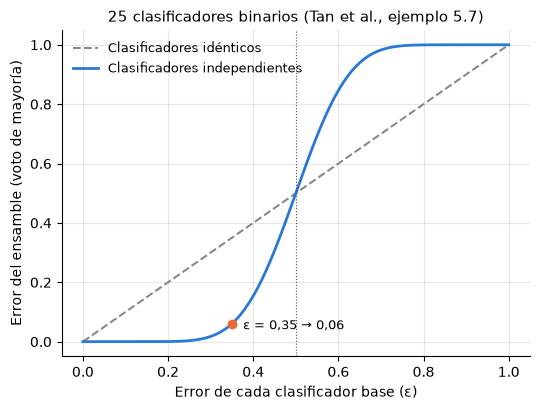

In [5]:
## Error de la mayoría de 25 clasificadores binarios independientes, cada uno con error eps
def error_mayoria(eps, n=25):
    ## P(13 o más de 25 se equivocan) = P(X > 12), con X ~ Binomial(25, eps)
    return binom.sf(n // 2, n, eps)


print(f"Error con eps = 0,35: clasificadores idénticos 0.350 | independientes {error_mayoria(0.35):.3f}")

eps = np.linspace(0, 1, 201)
fig, ax = plt.subplots(figsize=(5.5, 4.2))
ax.plot(eps, eps, color=GRIS, linestyle="--", linewidth=1.5, label="Clasificadores idénticos")
ax.plot(eps, error_mayoria(eps), color=AZUL, linewidth=2, label="Clasificadores independientes")
ax.axvline(0.5, color="#52514e", linewidth=0.8, linestyle=":")
ax.scatter([0.35], [error_mayoria(0.35)], color=NARANJA, zorder=3)
ax.annotate("ε = 0,35 → 0,06", xy=(0.35, error_mayoria(0.35)), xytext=(8, -4),
            textcoords="offset points", fontsize=9)
ax.set_xlabel("Error de cada clasificador base (ε)")
ax.set_ylabel("Error del ensamble (voto de mayoría)")
ax.set_title("25 clasificadores binarios (Tan et al., ejemplo 5.7)")
ax.legend(frameon=False, fontsize=9)
plt.tight_layout()
plt.show()

### 2.2 La varianza de un árbol profundo y el promedio de muchos

**▶ En vivo.** Tan et al. (sección 5.6.3) descomponen el error esperado de un clasificador en **sesgo** (supuestos rígidos sobre la frontera de decisión), **varianza** (cuánto cambia el modelo cuando cambian los datos de entrenamiento) y **ruido** (error irreducible). Un árbol profundo tiene poco sesgo y mucha varianza; un árbol de profundidad 3, lo contrario.

El *bagging* (*bootstrap aggregating*; Breiman, 1996; Tan et al., sección 5.6.4) ajusta un árbol en cada muestra *bootstrap* del entrenamiento (muestreo con reemplazo, del mismo tamaño) y promedia sus predicciones. El experimento:
1. Ajustamos 50 árboles profundos, cada uno en una muestra *bootstrap* distinta, y medimos el macro F1 de **cada uno** en validación.
2. Promediamos las probabilidades de los primeros $k$ árboles, para $k = 1, \dots, 50$.
3. Repetimos lo mismo con árboles de profundidad 3.
4. Para ver la varianza **del ensamble**, repetimos 10 veces un *bagging* de 25 árboles con semillas distintas.

In [6]:
## 50 árboles, cada uno ajustado en una muestra bootstrap distinta del entrenamiento
def arboles_bootstrap(profundidad, n_arboles=50):
    rng = np.random.default_rng(86)
    probas, f1s = [], []
    for _ in range(n_arboles):
        idx = rng.integers(0, len(X_train), len(X_train))          ## muestra con reemplazo
        arbol = DecisionTreeClassifier(max_depth=profundidad, random_state=86)
        arbol.fit(X_train.iloc[idx], y_train_c[idx])
        p = arbol.predict_proba(X_val)
        probas.append(p)
        f1s.append(macro_f1(y_val_c, p.argmax(axis=1)))
    probas = np.array(probas)                                       ## (árboles, casos, clases)
    ## Varianza: cuánto cambia, de un árbol a otro, la probabilidad que cada caso recibe para su clase verdadera
    p_correcta = probas[:, np.arange(len(y_val_c)), y_val_c]
    varianza = p_correcta.var(axis=0).mean()
    ## Curva: macro F1 del promedio de los primeros k árboles
    acumulado = np.cumsum(probas, axis=0)
    curva = [macro_f1(y_val_c, acumulado[k].argmax(axis=1)) for k in range(n_arboles)]
    ## Proporción de árboles que no predicen alguna de las 5 clases
    sin_clase = np.mean([len(np.unique(p.argmax(axis=1))) < 5 for p in probas])
    return np.array(f1s), np.array(curva), varianza, sin_clase


t0 = time.perf_counter()
f1_prof, curva_prof, var_prof, sin_prof = arboles_bootstrap(profundidad=None)
f1_p3, curva_p3, var_p3, sin_p3 = arboles_bootstrap(profundidad=3)
print("Varianza media, entre árboles, de la probabilidad asignada a la clase correcta: "
      f"profundos {var_prof:.3f} | profundidad 3 {var_p3:.3f}")
print(f"Árboles que no predicen alguna de las 5 clases: profundos {sin_prof:.0%} | profundidad 3 {sin_p3:.0%}")


## 10 repeticiones de un bagging de 25 árboles (semillas distintas): ¿cuánto varía el ensamble?
def repetir_bagging(profundidad, repeticiones=10):
    return np.array([
        macro_f1(y_val_c, BaggingClassifier(DecisionTreeClassifier(max_depth=profundidad), n_estimators=25,
                                            n_jobs=N_HILOS, random_state=s).fit(X_train, y_train_c).predict(X_val))
        for s in range(repeticiones)
    ])


bag_prof, bag_p3 = repetir_bagging(None), repetir_bagging(3)
print(f"Tiempo: {time.perf_counter() - t0:.1f} s")

resumen = pd.DataFrame({
    "Árbol profundo (50 muestras bootstrap)": pd.Series(f1_prof),
    "Bagging de 25 árboles profundos (10 repeticiones)": pd.Series(bag_prof),
    "Árbol de profundidad 3 (50 muestras bootstrap)": pd.Series(f1_p3),
    "Bagging de 25 árboles de profundidad 3 (10 repeticiones)": pd.Series(bag_p3),
}).agg(["mean", "std", "min", "max"]).T
resumen.columns = ["Macro F1 medio (val)", "DE", "Mínimo", "Máximo"]
resumen.round(3)

Varianza media, entre árboles, de la probabilidad asignada a la clase correcta: profundos 0.168 | profundidad 3 0.009
Árboles que no predicen alguna de las 5 clases: profundos 0% | profundidad 3 46%


Tiempo: 9.9 s


,Macro F1 medio (val),DE,Mínimo,Máximo
Árbol profundo (50 muestras bootstrap),0.557,0.010,0.536,0.578
Bagging de 25 árboles profundos (10 repeticiones),0.660,0.004,0.651,0.663
Árbol de profundidad 3 (50 muestras bootstrap),0.404,0.027,0.337,0.449
Bagging de 25 árboles de profundidad 3 (10 repeticiones),0.474,0.006,0.461,0.482


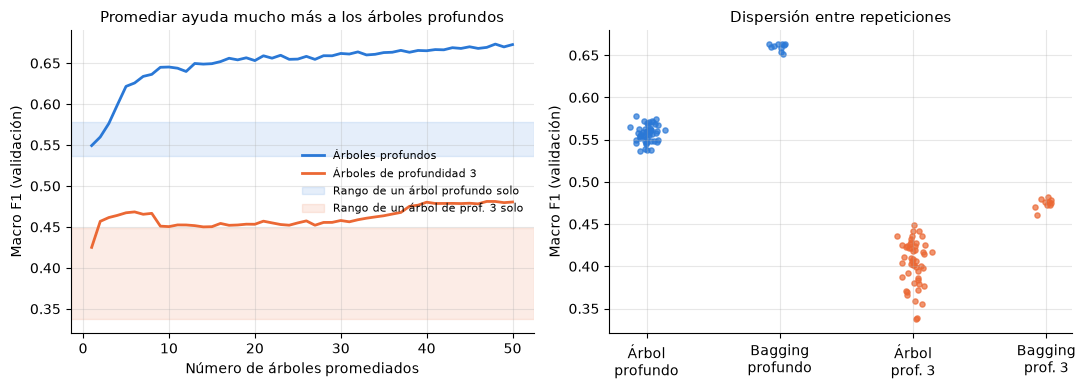

In [7]:
## Macro F1 en validación según el número de árboles promediados
k = np.arange(1, len(curva_prof) + 1)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

ax = axes[0]
ax.plot(k, curva_prof, color=AZUL, linewidth=2, label="Árboles profundos")
ax.plot(k, curva_p3, color=NARANJA, linewidth=2, label="Árboles de profundidad 3")
ax.axhspan(f1_prof.min(), f1_prof.max(), color=AZUL, alpha=0.12, label="Rango de un árbol profundo solo")
ax.axhspan(f1_p3.min(), f1_p3.max(), color=NARANJA, alpha=0.12, label="Rango de un árbol de prof. 3 solo")
ax.set_xlabel("Número de árboles promediados")
ax.set_ylabel("Macro F1 (validación)")
ax.set_title("Promediar ayuda mucho más a los árboles profundos")
ax.legend(frameon=False, fontsize=8, loc="center right")

ax = axes[1]
datos_caja = [f1_prof, bag_prof, f1_p3, bag_p3]
nombres_caja = ["Árbol\nprofundo", "Bagging\nprofundo", "Árbol\nprof. 3", "Bagging\nprof. 3"]
for i, (d, c) in enumerate(zip(datos_caja, [AZUL, AZUL, NARANJA, NARANJA])):
    x_j = np.random.default_rng(86).normal(i, 0.05, len(d))
    ax.scatter(x_j, d, s=14, color=c, alpha=0.7)
ax.set_xticks(range(4), nombres_caja)
ax.set_ylabel("Macro F1 (validación)")
ax.set_title("Dispersión entre repeticiones")
plt.tight_layout()
plt.show()

**Para recordar.**
- Un árbol profundo cambia mucho de una muestra a otra (**alta varianza**): la probabilidad que asigna a la clase correcta de un mismo caso varía unas 20 veces más entre árboles profundos que entre árboles de profundidad 3. Promediar árboles ajustados en muestras *bootstrap* cancela buena parte de esa variación: el *bagging* de 25 árboles profundos supera a **todos** los árboles individuales (≈ 0,66 frente a un máximo de ≈ 0,58) y varía menos entre repeticiones.
- Con árboles de profundidad 3 el promedio también ayuda (de ≈ 0,40 a ≈ 0,47), en parte porque el promedio de fronteras simples distintas representa fronteras más complejas (Tan et al., sección 5.6.4, lo muestran con árboles de un solo nivel). Pero queda muy lejos de los árboles profundos: su error proviene sobre todo del **sesgo**, que el promedio no corrige. El *bagging* rinde más con clasificadores **inestables** (Tan et al., sección 5.6.4).
- Ojo: el macro F1 de los árboles de profundidad 3 se dispersa más que el de los profundos, aunque sus probabilidades sean más estables. Con solo 8 hojas, casi la mitad de esos árboles no predice alguna de las 5 clases, y el macro F1 castiga mucho una clase ausente. La dispersión de una métrica no es lo mismo que la varianza de las predicciones.
- La ganancia tiene un límite. Si cada árbol tiene varianza $\sigma^2$ y la correlación entre pares de árboles es $\rho$, la varianza del promedio de $B$ árboles es $\rho\sigma^2 + \frac{1-\rho}{B}\sigma^2$ (Hastie, Tibshirani y Friedman, 2009, sección 15.2). Agregar árboles elimina el segundo término, no el primero: para seguir mejorando hay que **descorrelacionar** los árboles. Es la idea del random forest (sección 4).

## 3. Votación dura y blanda

**▶ En vivo.** `VotingClassifier` combina modelos **distintos** ajustados sobre los mismos datos:
- **Votación dura** (`voting="hard"`): cada modelo vota por una clase y gana la mayoría.
- **Votación blanda** (`voting="soft"`): se promedian las **probabilidades** de cada clase y gana la de mayor promedio. Usa más información (cuán seguro está cada modelo), pero supone que las probabilidades de los distintos modelos son comparables, es decir, **razonablemente calibradas** (S9, sección 9).

Combinamos tres modelos de S8 con sesgos distintos: regresión logística (frontera lineal), random forest (árboles) y k-NN (vecindad). Los dos últimos con escalado dentro del pipeline cuando corresponde. Junto al macro F1 mostramos la **confianza media** de cada modelo (el promedio de la probabilidad máxima que asigna) y su **exactitud**: en un modelo bien calibrado, ambas cifras son parecidas.

In [8]:
## Modelos base (los escalados van dentro de un Pipeline, como en S9)
logit = Pipeline([("escalar", StandardScaler()), ("modelo", LogisticRegression(max_iter=1000))])
knn = Pipeline([("escalar", StandardScaler()), ("modelo", KNeighborsClassifier(n_neighbors=15))])
rf_200 = RandomForestClassifier(n_estimators=200, n_jobs=N_HILOS, random_state=86)
nb = GaussianNB()
nb_cal = CalibratedClassifierCV(GaussianNB(), method="isotonic", cv=cv5)

nombres = {"logit": "Regresión logística", "rf": "Random forest (200 árboles)", "knn": "k-NN (k = 15)",
           "nb": "Naive Bayes gaussiano", "nb_cal": "Naive Bayes + calibración isotónica"}
base_votacion = {"logit": logit, "rf": rf_200, "knn": knn, "nb": nb, "nb_cal": nb_cal}

filas = []
for clave, modelo in base_votacion.items():
    modelo.fit(X_train, y_train_c)
    p = modelo.predict_proba(X_val)
    filas.append({"Modelo": nombres[clave], "Macro F1 (val)": macro_f1(y_val_c, p.argmax(axis=1)),
                  "Exactitud (val)": accuracy_score(y_val_c, p.argmax(axis=1)),
                  "Confianza media": p.max(axis=1).mean()})
pd.DataFrame(filas).set_index("Modelo").round(3)

,Macro F1 (val),Exactitud (val),Confianza media
Modelo,,,
Regresión logística,0.525,0.532,0.504
Random forest (200 árboles),0.668,0.671,0.605
k-NN (k = 15),0.567,0.567,0.591
Naive Bayes gaussiano,0.330,0.386,0.623
Naive Bayes + calibración isotónica,0.448,0.455,0.439


In [9]:
## Votación dura vs blanda con tres conjuntos de miembros
conjuntos = {
    "Logística + RF + k-NN": ["logit", "rf", "knn"],
    "… + Naive Bayes": ["logit", "rf", "knn", "nb"],
    "… + Naive Bayes calibrado": ["logit", "rf", "knn", "nb_cal"],
}
filas = []
t0 = time.perf_counter()
for nombre, claves in conjuntos.items():
    fila = {"Miembros": nombre}
    for tipo in ["hard", "soft"]:
        votacion = VotingClassifier([(c, base_votacion[c]) for c in claves], voting=tipo)
        votacion.fit(X_train, y_train_c)
        fila[f"Macro F1 ({'dura' if tipo == 'hard' else 'blanda'})"] = macro_f1(y_val_c, votacion.predict(X_val))
    filas.append(fila)
print(f"Tiempo: {time.perf_counter() - t0:.1f} s")
tabla_votacion = pd.DataFrame(filas).set_index("Miembros")
tabla_votacion.round(3)

Tiempo: 6.4 s


,Macro F1 (dura),Macro F1 (blanda)
Miembros,,
Logística + RF + k-NN,0.614,0.639
… + Naive Bayes,0.593,0.608
… + Naive Bayes calibrado,0.590,0.627


**Para recordar.**
- Con los mismos tres miembros, la votación **blanda** supera a la dura: un voto de 0,9 y uno de 0,4 no pesan lo mismo, y la votación dura descarta esa diferencia.
- Naive Bayes es el ejemplo de S9: ordena bien, pero sus probabilidades son **extremas** (confianza media muy superior a su exactitud). En la votación blanda su opinión pesa demasiado y arrastra al conjunto. Calibrarlo antes con `CalibratedClassifierCV` recupera buena parte de la pérdida: la votación blanda exige probabilidades comparables.
- Ninguna votación supera aquí al random forest solo. Un ensamble por votación ayuda cuando los miembros tienen desempeños **parecidos** y errores **poco correlacionados** (sección 2.1). Si un miembro es mucho mejor que los demás, los votos de los débiles lo diluyen. Se pueden dar pesos distintos (`weights=`), pero esos pesos son hiperparámetros: se eligen con validación cruzada, no mirando validación.

## 4. Bagging y random forest

Un **random forest** (Breiman, 2001) es *bagging* de árboles con un ingrediente adicional: en cada división, el árbol solo considera un subconjunto aleatorio de `max_features` predictores. Esto **descorrelaciona** los árboles (sección 2.2), a costa de que cada uno sea algo peor.

Comparamos `BaggingClassifier` con árboles completos (que usa los 8 predictores en cada división) con `RandomForestClassifier`, ambos con 200 árboles.

**Puntaje OOB** (*out-of-bag*). Cada muestra *bootstrap* deja fuera alrededor de un 37% de los casos ($1 - 0{,}632$; Tan et al., sección 5.6.4). Si cada caso de entrenamiento se predice solo con los árboles que no lo vieron, se obtiene una estimación del desempeño **sin un conjunto aparte**. Como en S8, calculamos el puntaje OOB con macro F1: `BaggingClassifier` solo admite exactitud en `oob_score`, así que lo calculamos a partir de `oob_decision_function_`, que contiene las probabilidades fuera de la bolsa de cada caso.

In [10]:
## Bagging de árboles completos vs random forest (200 árboles cada uno)
def oob_macro_f1(modelo):
    ## Probabilidades out-of-bag de cada caso de entrenamiento -> clase -> macro F1
    return macro_f1(y_train_c, modelo.oob_decision_function_.argmax(axis=1))


modelos_bag = {
    "Bagging de árboles (8 predictores por división)":
        BaggingClassifier(DecisionTreeClassifier(), n_estimators=200, oob_score=True, n_jobs=N_HILOS, random_state=86),
    "Random forest (max_features='sqrt' → 2)":
        RandomForestClassifier(n_estimators=200, oob_score=True, n_jobs=N_HILOS, random_state=86),
}
filas = []
for nombre, modelo in modelos_bag.items():
    t0 = time.perf_counter()
    modelo.fit(X_train, y_train_c)
    filas.append({"Modelo": nombre, "Macro F1 OOB (entrenamiento)": oob_macro_f1(modelo),
                  "Macro F1 (val)": macro_f1(y_val_c, modelo.predict(X_val)), "Tiempo (s)": time.perf_counter() - t0})
pd.DataFrame(filas).set_index("Modelo").round(3)

,Macro F1 OOB (entrenamiento),Macro F1 (val),Tiempo (s)
Modelo,,,
Bagging de árboles (8 predictores por división),0.684,0.676,2.377
Random forest (max_features='sqrt' → 2),0.683,0.668,1.101


### 4.1 El efecto de `max_features`

Variamos `max_features` entre 1 y 8 (con 8, el random forest es *bagging*). Para cada valor medimos el macro F1 OOB, el de validación y el **acuerdo medio entre árboles**: la proporción de casos de validación en que dos árboles del bosque predicen la misma clase, promediada sobre los pares de los primeros 50 árboles. Es una medida directa de cuán correlacionados están.

Tiempo: 9.6 s


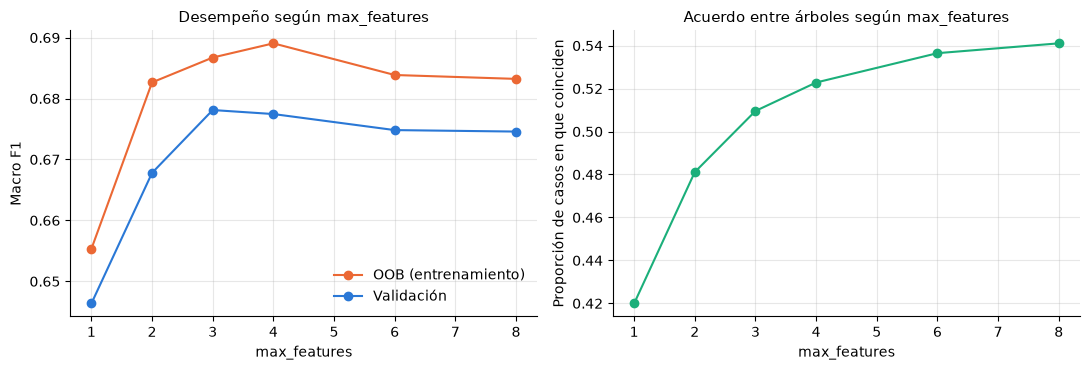

,Macro F1 OOB,Macro F1 (val),Acuerdo medio entre árboles
max_features,,,
1,0.655,0.646,0.420
2,0.683,0.668,0.481
3,0.687,0.678,0.510
4,0.689,0.677,0.523
6,0.684,0.675,0.536
8,0.683,0.675,0.541


In [11]:
## max_features de 1 a 8: desempeño y acuerdo entre árboles
def acuerdo_medio(bosque, n_arboles=50):
    preds = np.array([arbol.predict(X_val.to_numpy()) for arbol in bosque.estimators_[:n_arboles]])
    i, j = np.triu_indices(n_arboles, k=1)
    return np.mean([(preds[a] == preds[b]).mean() for a, b in zip(i, j)])


t0 = time.perf_counter()
filas = []
for m in [1, 2, 3, 4, 6, 8]:
    bosque = RandomForestClassifier(n_estimators=200, max_features=m, oob_score=True,
                                    n_jobs=N_HILOS, random_state=86).fit(X_train, y_train_c)
    filas.append({"max_features": m, "Macro F1 OOB": oob_macro_f1(bosque),
                  "Macro F1 (val)": macro_f1(y_val_c, bosque.predict(X_val)),
                  "Acuerdo medio entre árboles": acuerdo_medio(bosque)})
tabla_mf = pd.DataFrame(filas).set_index("max_features")
print(f"Tiempo: {time.perf_counter() - t0:.1f} s")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(tabla_mf.index, tabla_mf["Macro F1 OOB"], "o-", color=NARANJA, label="OOB (entrenamiento)")
axes[0].plot(tabla_mf.index, tabla_mf["Macro F1 (val)"], "o-", color=AZUL, label="Validación")
axes[0].set_xlabel("max_features")
axes[0].set_ylabel("Macro F1")
axes[0].set_title("Desempeño según max_features")
axes[0].legend(frameon=False)
axes[1].plot(tabla_mf.index, tabla_mf["Acuerdo medio entre árboles"], "o-", color=VERDE)
axes[1].set_xlabel("max_features")
axes[1].set_ylabel("Proporción de casos en que coinciden")
axes[1].set_title("Acuerdo entre árboles según max_features")
plt.tight_layout()
plt.show()
tabla_mf.round(3)

**Para recordar.**
- El puntaje OOB queda cerca del de validación: es una estimación casi gratuita del desempeño, útil cuando los datos son escasos. Aquí es algo más alto que el de validación; ambos son estimaciones con ruido de alrededor de ±0,01.
- Con `max_features` bajo, los árboles coinciden menos (están menos correlacionados), pero cada uno es más débil. El óptimo está en un punto intermedio. El valor por defecto (`"sqrt"`, aquí 2) no es necesariamente el mejor: en estos datos, incluso el *bagging* (8) lo supera en validación. `max_features` es un hiperparámetro que conviene ajustar (sección 7).
- *Bagging* y random forest se pueden ajustar **en paralelo** (cada árbol es independiente). El *boosting*, que veremos ahora, no.

## 5. Boosting

**▶ En vivo.** El *boosting* construye el ensamble **secuencialmente**: cada modelo nuevo se concentra en lo que los anteriores hacen mal. Sus modelos base suelen ser árboles **poco profundos** (alto sesgo, baja varianza), y el ensamble reduce sobre todo el sesgo, al revés que el *bagging*.

### 5.1 AdaBoost

**AdaBoost** (Freund y Schapire, 1997; Tan et al., sección 5.6.5) reajusta los **pesos de los casos**: tras cada ronda, los mal clasificados ganan peso y el árbol siguiente se esfuerza por acertarlos. Cada árbol vota con un peso que depende de su error. scikit-learn implementa la variante multiclase SAMME. Usamos 300 árboles de profundidad 3 y `learning_rate=0.5`, y seguimos el macro F1 ronda a ronda con `staged_predict`.

AdaBoost: macro F1 (val) = 0.600 con 300 árboles | mejor en validación = 0.601 (ronda 294) | 8.7 s


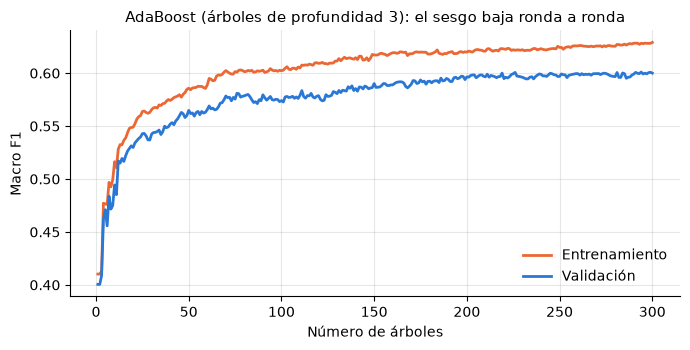

In [12]:
## AdaBoost con árboles de profundidad 3
## Nota de versión: con scikit-learn 1.9.1, staged_predict emite un aviso espurio sobre los nombres de las
## columnas si el modelo se ajustó con un DataFrame. Por eso aquí usamos arreglos NumPy (.to_numpy()).
X_train_np, X_val_np = X_train.to_numpy(), X_val.to_numpy()
t0 = time.perf_counter()
ada = AdaBoostClassifier(DecisionTreeClassifier(max_depth=3), n_estimators=300, learning_rate=0.5, random_state=86)
ada.fit(X_train_np, y_train_c)
t_ada = time.perf_counter() - t0
curva_ada_val = [macro_f1(y_val_c, p) for p in ada.staged_predict(X_val_np)]
curva_ada_train = [macro_f1(y_train_c, p) for p in ada.staged_predict(X_train_np)]
print(f"AdaBoost: macro F1 (val) = {curva_ada_val[-1]:.3f} con {len(curva_ada_val)} árboles | "
      f"mejor en validación = {max(curva_ada_val):.3f} (ronda {int(np.argmax(curva_ada_val)) + 1}) | {t_ada:.1f} s")

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(np.arange(1, 301), curva_ada_train, color=NARANJA, linewidth=2, label="Entrenamiento")
ax.plot(np.arange(1, 301), curva_ada_val, color=AZUL, linewidth=2, label="Validación")
ax.set_xlabel("Número de árboles")
ax.set_ylabel("Macro F1")
ax.set_title("AdaBoost (árboles de profundidad 3): el sesgo baja ronda a ronda")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

### 5.2 Gradient boosting: `HistGradientBoostingClassifier`

El **gradient boosting** (Friedman, 2001) generaliza la idea: cada árbol nuevo se ajusta al **gradiente de la función de pérdida** respecto de las predicciones del ensamble actual (con pérdida cuadrática, a los residuos). `GradientBoostingClassifier` es la versión clásica; `HistGradientBoostingClassifier` agrupa cada predictor en a lo sumo 255 intervalos antes de buscar divisiones, lo que la hace mucho más rápida con miles de casos. Acepta valores faltantes y tiene **parada temprana** incorporada:
- `early_stopping=True` reserva internamente el 10% del entrenamiento (`validation_fraction=0.1`);
- se detiene cuando la pérdida en esa porción no mejora durante 10 iteraciones (`n_iter_no_change=10`).

Así, el número de iteraciones se elige **sin mirar** nuestro conjunto de validación.

In [13]:
## HistGradientBoosting con parada temprana interna (10% del entrenamiento)
t0 = time.perf_counter()
hgb = HistGradientBoostingClassifier(max_iter=1000, learning_rate=0.1, early_stopping=True,
                                     validation_fraction=0.1, n_iter_no_change=10, random_state=86)
hgb.fit(X_train, y_train_c)
t_hgb = time.perf_counter() - t0
f1_hgb = macro_f1(y_val_c, hgb.predict(X_val))
print(f"HistGradientBoosting: macro F1 (val) = {f1_hgb:.3f} | iteraciones = {hgb.n_iter_} | {t_hgb:.1f} s")

HistGradientBoosting: macro F1 (val) = 0.683 | iteraciones = 98 | 1.0 s


### 5.3 XGBoost con parada temprana en una porción del entrenamiento

**▶ En vivo.** En S8 usamos el conjunto de **validación** para la parada temprana de XGBoost (Chen y Guestrin, 2016) y advertimos que eso volvía optimista su macro F1 de validación: el número de árboles se había elegido mirando esos mismos datos. Ahora lo hacemos bien:
1. Separamos un 15% del **entrenamiento** (estratificado) como conjunto de parada (`X_parada`).
2. XGBoost se ajusta con el 85% restante y se detiene cuando la pérdida en `X_parada` no mejora en 50 rondas.
3. El conjunto de validación queda **limpio**: solo se usa para comparar el modelo final con los demás.

El costo es entrenar con un 15% menos de casos. Una alternativa es reajustar después con todo el entrenamiento y el número de árboles elegido.

Comparamos dos tasas de aprendizaje (`learning_rate`): 0,3 y 0,05.

In [14]:
## Conjunto de parada: 15% del ENTRENAMIENTO (validación no se toca)
X_ajuste, X_parada, y_ajuste, y_parada = train_test_split(
    X_train, y_train_c, test_size=0.15, stratify=y_train_c, random_state=86)

parametros_xgb = dict(max_depth=6, subsample=0.8, colsample_bytree=0.8, eval_metric="mlogloss",
                      tree_method="hist", n_jobs=N_HILOS, random_state=86)
filas, xgb_es = [], {}
for lr in [0.3, 0.05]:
    t0 = time.perf_counter()
    modelo = xgb.XGBClassifier(n_estimators=3000, learning_rate=lr, early_stopping_rounds=50, **parametros_xgb)
    modelo.fit(X_ajuste, y_ajuste, eval_set=[(X_parada, y_parada)], verbose=False)
    xgb_es[lr] = modelo
    filas.append({"learning_rate": lr, "Árboles usados (mejor iteración)": modelo.best_iteration + 1,
                  "Árboles ajustados": modelo.best_iteration + 51,
                  "Macro F1 (val)": macro_f1(y_val_c, modelo.predict(X_val)),
                  "Tiempo (s)": time.perf_counter() - t0})
tabla_xgb = pd.DataFrame(filas).set_index("learning_rate")
tabla_xgb.round(3)

,Árboles usados (mejor iteración),Árboles ajustados,Macro F1 (val),Tiempo (s)
learning_rate,,,,
0.30,68,118,0.675,0.595
0.05,547,597,0.690,2.057


**Tasa de aprendizaje y número de árboles.** Para ver la relación completa, ajustamos ambos modelos **sin** parada temprana hasta 1.000 rondas y calculamos el macro F1 en validación con los primeros $k$ árboles (`iteration_range`). Las líneas verticales marcan la iteración elegida por la parada temprana, que no miró validación.

Tiempo: 10.6 s


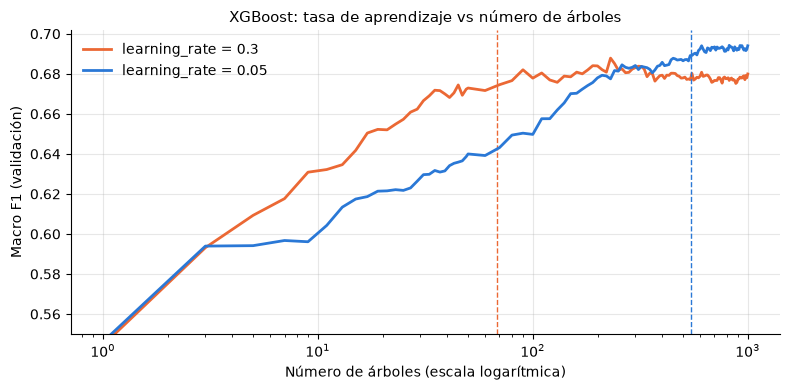

In [15]:
## Curvas de macro F1 (validación) según el número de árboles, sin parada temprana
N_RONDAS = 1000
pasos = np.unique(np.r_[np.arange(1, 50, 2), np.arange(50, N_RONDAS + 1, 10)])
curvas_xgb = {}
t0 = time.perf_counter()
for lr in [0.3, 0.05]:
    modelo = xgb.XGBClassifier(n_estimators=N_RONDAS, learning_rate=lr, **parametros_xgb)
    modelo.fit(X_ajuste, y_ajuste, verbose=False)
    curvas_xgb[lr] = [macro_f1(y_val_c, modelo.predict(X_val, iteration_range=(0, int(k)))) for k in pasos]
print(f"Tiempo: {time.perf_counter() - t0:.1f} s")

fig, ax = plt.subplots(figsize=(8, 4))
for lr, color in [(0.3, NARANJA), (0.05, AZUL)]:
    ax.plot(pasos, curvas_xgb[lr], color=color, linewidth=2, label=f"learning_rate = {lr}")
    ax.axvline(xgb_es[lr].best_iteration + 1, color=color, linestyle="--", linewidth=1)
ax.set_xscale("log")
ax.set_ylim(0.55, None)
ax.set_xlabel("Número de árboles (escala logarítmica)")
ax.set_ylabel("Macro F1 (validación)")
ax.set_title("XGBoost: tasa de aprendizaje vs número de árboles")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

In [16]:
## Resumen de boosting (y random forest de la sección 3 como referencia)
pd.DataFrame([
    {"Modelo": "Random forest (200 árboles, sección 3)", "Macro F1 (val)": macro_f1(y_val_c, rf_200.predict(X_val)),
     "Árboles / iteraciones": 200},
    {"Modelo": "AdaBoost (300 árboles de prof. 3)", "Macro F1 (val)": curva_ada_val[-1], "Árboles / iteraciones": 300},
    {"Modelo": "HistGradientBoosting (parada temprana)", "Macro F1 (val)": f1_hgb, "Árboles / iteraciones": hgb.n_iter_},
    {"Modelo": "XGBoost, lr = 0,3 (parada temprana)", "Macro F1 (val)": tabla_xgb.loc[0.3, "Macro F1 (val)"],
     "Árboles / iteraciones": xgb_es[0.3].best_iteration + 1},
    {"Modelo": "XGBoost, lr = 0,05 (parada temprana)", "Macro F1 (val)": tabla_xgb.loc[0.05, "Macro F1 (val)"],
     "Árboles / iteraciones": xgb_es[0.05].best_iteration + 1},
]).set_index("Modelo").round(3)

,Macro F1 (val),Árboles / iteraciones
Modelo,,
"Random forest (200 árboles, sección 3)",0.668,200
AdaBoost (300 árboles de prof. 3),0.600,300
HistGradientBoosting (parada temprana),0.683,98
"XGBoost, lr = 0,3 (parada temprana)",0.675,68
"XGBoost, lr = 0,05 (parada temprana)",0.690,547


**Para recordar.**
- AdaBoost parte de árboles débiles y mejora ronda a ronda: el macro F1 sube a la vez en entrenamiento y en validación, señal de que lo que baja es el sesgo. Tras 300 árboles sigue bajo el random forest; la curva aún sube lentamente, de modo que más rondas o árboles algo más profundos lo acercarían, a costa de tiempo.
- El *gradient boosting* moderno (`HistGradientBoosting`, XGBoost) es el más fuerte de la tabla, como en S8. Grinsztajn, Oyallon y Varoquaux (2022) muestran que los ensambles de árboles siguen superando a las redes neuronales en datos tabulares típicos.
- `learning_rate` y el número de árboles se compensan: con 0,3 la curva sube rápido y se estanca cerca de 0,68 desde unos 100 árboles; con 0,05 se necesitan varios cientos de árboles para llegar a ese nivel, pero termina más arriba (≈ 0,69). Una tasa baja con más árboles suele generalizar mejor, a costa de tiempo.
- La parada temprana elige el número de árboles. Para que la validación siga siendo honesta, el conjunto de parada debe salir del **entrenamiento**.
- La parada temprana vigila la **pérdida logarítmica** (`mlogloss`), no el macro F1. Con 0,3 se detuvo antes del máximo de macro F1: la pérdida empieza a subir cuando el modelo se vuelve demasiado confiado en sus probabilidades, aunque las clases predichas todavía mejoren un poco. Si lo que importa es el macro F1, el número de árboles puede ajustarse también por validación cruzada (sección 7).

## 6. Stacking

**▶ En vivo.** El *stacking* (*stacked generalization*; Wolpert, 1992) aprende **cómo combinar** los modelos base: un **meta-aprendiz** (aquí, una regresión logística) recibe como predictores las probabilidades que predice cada modelo base y aprende a ponderarlas.

La condición clave: el meta-aprendiz debe entrenarse con predicciones **fuera de la muestra** (*out-of-fold*). Hastie et al. (2009, sección 8.8) lo explican así: si los pesos se aprenden con predicciones de modelos que ya vieron esos casos, el meta-aprendiz premiará al modelo que **más memoriza**, no al que mejor generaliza.

`StackingClassifier(cv=5)` lo hace bien:
1. Para cada modelo base, `cross_val_predict` con 5 pliegues: cada caso de entrenamiento se predice con un modelo que no lo vio.
2. El meta-aprendiz se ajusta con esas predicciones fuera de la muestra.
3. Los modelos base se reajustan con todo el entrenamiento para predecir casos nuevos.

Modelos base: regresión logística, k-NN, random forest y `HistGradientBoosting`.

In [17]:
## Stacking correcto: predicciones out-of-fold (cv=5) y regresión logística como meta-aprendiz
modelos_base = [
    ("logit", logit),
    ("knn", knn),
    ("rf", RandomForestClassifier(n_estimators=200, n_jobs=N_HILOS, random_state=86)),
    ("hgb", HistGradientBoostingClassifier(random_state=86)),
]
t0 = time.perf_counter()
stack = StackingClassifier(modelos_base, final_estimator=LogisticRegression(max_iter=1000), cv=cv5)
stack.fit(X_train, y_train_c)
print(f"StackingClassifier ajustado en {time.perf_counter() - t0:.1f} s")

## Desempeño de cada modelo base (reajustado con todo el entrenamiento) en validación
f1_base = {nombre: macro_f1(y_val_c, m.predict(X_val)) for nombre, m in stack.named_estimators_.items()}
print("Modelos base, macro F1 (val):", {k: round(v, 3) for k, v in f1_base.items()})

StackingClassifier ajustado en 11.0 s


Modelos base, macro F1 (val): {'logit': 0.525, 'knn': 0.567, 'rf': 0.668, 'hgb': 0.683}


**La forma incorrecta.** Ahora hacemos el *stacking* a mano y **mal**: los modelos base se ajustan con todo el entrenamiento, predicen **ese mismo entrenamiento** y el meta-aprendiz se ajusta con esas predicciones dentro de la muestra. Para comparar en igualdad de condiciones, reconstruimos también la versión correcta a mano: las predicciones fuera de la muestra se obtienen con `cross_val_predict` y los mismos pliegues, que es lo que `StackingClassifier` hace por dentro.

En ambos casos, el desempeño "en entrenamiento" del meta-aprendiz se mide sobre los mismos datos con que se ajustó, que es lo que vería quien no tiene un conjunto de validación.

In [18]:
## Predicciones de los modelos base para el meta-aprendiz
## (a) DENTRO de la muestra: modelos ajustados con todo el entrenamiento predicen ese mismo entrenamiento (fuga)
Z_dentro = np.hstack([m.predict_proba(X_train) for m in stack.named_estimators_.values()])
## (b) FUERA de la muestra: cada caso predicho por un modelo que no lo vio (lo que hace StackingClassifier)
t0 = time.perf_counter()
Z_fuera = np.hstack([cross_val_predict(m, X_train, y_train_c, cv=cv5, method="predict_proba")
                     for _, m in modelos_base])
print(f"Predicciones fuera de la muestra en {time.perf_counter() - t0:.1f} s")
## En validación, ambas versiones usan los modelos base ajustados con todo el entrenamiento
Z_val = np.hstack([m.predict_proba(X_val) for m in stack.named_estimators_.values()])

meta_mal = LogisticRegression(max_iter=1000).fit(Z_dentro, y_train_c)
meta_bien = LogisticRegression(max_iter=1000).fit(Z_fuera, y_train_c)
print("¿El meta-aprendiz a mano coincide con StackingClassifier? Predicciones iguales en validación:",
      f"{(meta_bien.predict(Z_val) == stack.predict(X_val)).mean():.1%}")

tabla_stack = pd.DataFrame([
    {"Versión": "Stacking correcto (out-of-fold, cv=5)",
     "Macro F1 en sus datos de ajuste": macro_f1(y_train_c, meta_bien.predict(Z_fuera)),
     "Macro F1 (val)": macro_f1(y_val_c, stack.predict(X_val))},
    {"Versión": "Stacking incorrecto (dentro de la muestra)",
     "Macro F1 en sus datos de ajuste": macro_f1(y_train_c, meta_mal.predict(Z_dentro)),
     "Macro F1 (val)": macro_f1(y_val_c, meta_mal.predict(Z_val))},
    {"Versión": "Mejor modelo base solo (HistGradientBoosting)", "Macro F1 en sus datos de ajuste": np.nan,
     "Macro F1 (val)": f1_base["hgb"]},
]).set_index("Versión")
tabla_stack.round(3)

Predicciones fuera de la muestra en 8.8 s


¿El meta-aprendiz a mano coincide con StackingClassifier? Predicciones iguales en validación: 100.0%


,Macro F1 en sus datos de ajuste,Macro F1 (val)
Versión,,
"Stacking correcto (out-of-fold, cv=5)",0.696,0.686
Stacking incorrecto (dentro de la muestra),1.000,0.675
Mejor modelo base solo (HistGradientBoosting),NaN,0.683


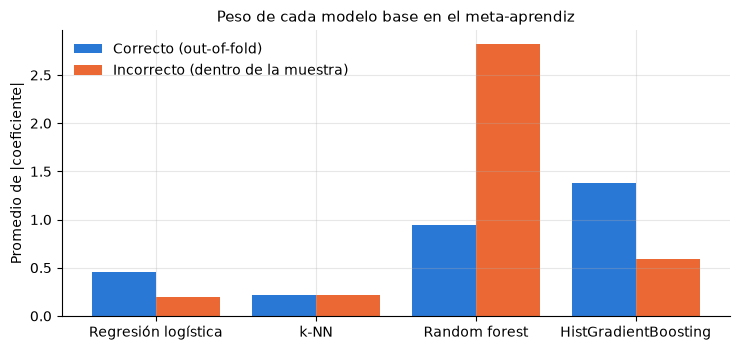

,Correcto (out-of-fold),Incorrecto (dentro de la muestra)
Regresión logística,0.45,0.19
k-NN,0.22,0.22
Random forest,0.95,2.83
HistGradientBoosting,1.37,0.59


In [19]:
## ¿A qué modelo base le da peso cada meta-aprendiz? Promedio de |coeficiente| sobre las 5 clases × 5 probabilidades
nombres_base = [n for n, _ in modelos_base]
peso = lambda meta: [np.abs(meta.coef_[:, 5 * i:5 * i + 5]).mean() for i in range(len(nombres_base))]
pesos = pd.DataFrame({"Correcto (out-of-fold)": peso(meta_bien), "Incorrecto (dentro de la muestra)": peso(meta_mal)},
                     index=["Regresión logística", "k-NN", "Random forest", "HistGradientBoosting"])

fig, ax = plt.subplots(figsize=(7.5, 3.6))
x = np.arange(len(pesos))
ax.bar(x - 0.2, pesos.iloc[:, 0], width=0.4, color=AZUL, label=pesos.columns[0])
ax.bar(x + 0.2, pesos.iloc[:, 1], width=0.4, color=NARANJA, label=pesos.columns[1])
ax.set_xticks(x, pesos.index)
ax.set_ylabel("Promedio de |coeficiente|")
ax.set_title("Peso de cada modelo base en el meta-aprendiz")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()
pesos.round(2)

**Para recordar.**
- Dentro de la muestra, el random forest predice el entrenamiento casi a la perfección (sus árboles vieron esos casos). El meta-aprendiz incorrecto aprende a **confiar en él** y su macro F1 en los datos de ajuste es prácticamente 1. En validación cae por debajo del *stacking* correcto e incluso del mejor modelo base solo.
- El meta-aprendiz correcto, entrenado con predicciones fuera de la muestra, reparte el peso de otra manera (más en `HistGradientBoosting`) y su desempeño en los datos de ajuste es una estimación realista del de validación.
- Es la misma lección de S9: **todo lo que aprende de los datos**, incluido el combinador de un ensamble, debe ajustarse con datos que los modelos anteriores no usaron.
- La ganancia del *stacking* sobre el mejor modelo solo es pequeña aquí: unas milésimas, y nula con la versión de scikit-learn de Colab. Suele ser mayor cuando los modelos base son buenos y distintos entre sí.

## 7. Ajuste de hiperparámetros

**▶ En vivo.** Ajustamos `HistGradientBoostingClassifier` (100 iteraciones fijas, sin parada temprana) con validación cruzada estratificada de **3 pliegues** dentro del entrenamiento y un presupuesto de **16 configuraciones** (48 ajustes) por método. Cuatro hiperparámetros:

| Hiperparámetro | Qué controla | Grilla (2 valores cada uno) | Búsqueda aleatoria / Optuna |
|---|---|---|---|
| `learning_rate` | contribución de cada árbol | 0,05 y 0,2 | log-uniforme en [0,01; 0,5] |
| `max_leaf_nodes` | complejidad de cada árbol | 15 y 63 | entero en [8, 64] |
| `min_samples_leaf` | casos mínimos por hoja | 10 y 50 | entero en [5, 100] |
| `l2_regularization` | penalización de los pesos de las hojas | 0 y 1 | uniforme en [0, 2] |

- **Búsqueda en grilla** (`GridSearchCV`): $2^4 = 16$ combinaciones. Prueba solo **dos valores** de cada hiperparámetro.
- **Búsqueda aleatoria** (`RandomizedSearchCV`): 16 combinaciones sorteadas. Prueba **16 valores distintos** de cada hiperparámetro. Bergstra y Bengio (2012) muestran que, cuando solo unos pocos hiperparámetros importan, la búsqueda aleatoria encuentra buenas configuraciones con muchos menos intentos que la grilla.
- **Optimización bayesiana con Optuna** (Akiba et al., 2019): elige cada nueva configuración a partir de los resultados anteriores (sección 7.2).

Todo ocurre **dentro del entrenamiento**; validación se usa una sola vez, al final, con la configuración ganadora.

In [20]:
## Grilla vs búsqueda aleatoria: mismo modelo, mismos pliegues, mismo presupuesto (16 configuraciones × 3 pliegues)
cv3 = StratifiedKFold(n_splits=3, shuffle=True, random_state=86)
hgb_base = HistGradientBoostingClassifier(max_iter=100, early_stopping=False, random_state=86)

grilla = {"learning_rate": [0.05, 0.2], "max_leaf_nodes": [15, 63],
          "min_samples_leaf": [10, 50], "l2_regularization": [0.0, 1.0]}
distribuciones = {"learning_rate": loguniform(0.01, 0.5), "max_leaf_nodes": randint(8, 65),
                  "min_samples_leaf": randint(5, 101), "l2_regularization": uniform(0, 2)}

t0 = time.perf_counter()
busqueda_grilla = GridSearchCV(hgb_base, grilla, cv=cv3, scoring="f1_macro", refit=False).fit(X_train, y_train_c)
t_grilla = time.perf_counter() - t0

t0 = time.perf_counter()
busqueda_azar = RandomizedSearchCV(hgb_base, distribuciones, n_iter=16, cv=cv3, scoring="f1_macro",
                                   random_state=86, refit=False).fit(X_train, y_train_c)
t_azar = time.perf_counter() - t0

redondear = lambda d: {k: (round(float(v), 3) if isinstance(v, float) else int(v)) for k, v in d.items()}
print(f"Grilla:    mejor macro F1 (CV) = {busqueda_grilla.best_score_:.4f} | {t_grilla:.1f} s | {redondear(busqueda_grilla.best_params_)}")
print(f"Aleatoria: mejor macro F1 (CV) = {busqueda_azar.best_score_:.4f} | {t_azar:.1f} s | {redondear(busqueda_azar.best_params_)}")

Grilla:    mejor macro F1 (CV) = 0.6872 | 53.5 s | {'l2_regularization': 1.0, 'learning_rate': 0.05, 'max_leaf_nodes': 63, 'min_samples_leaf': 10}
Aleatoria: mejor macro F1 (CV) = 0.6872 | 52.0 s | {'l2_regularization': 1.167, 'learning_rate': 0.125, 'max_leaf_nodes': 31, 'min_samples_leaf': 21}


### 7.1 Optuna

Optuna (Akiba et al., 2019) define el espacio de búsqueda **dentro de una función objetivo**: cada llamada `trial.suggest_*` propone un valor, y la función devuelve el puntaje de validación cruzada.
- **Muestreador TPE** (*Tree-structured Parzen Estimator*): tras unas configuraciones iniciales al azar (10 por defecto), separa las configuraciones probadas en "buenas" y "malas" y propone valores más probables entre las buenas. `seed=86` lo hace reproducible.
- **Poda** (*pruning*, opcional): reportamos el macro F1 acumulado tras cada pliegue; `MedianPruner` detiene un intento si va peor que la mediana de los intentos anteriores en ese mismo pliegue. Ahorra tiempo en configuraciones claramente malas.

Usamos **25 intentos** y los mismos 3 pliegues. Para comparar con el mismo presupuesto, también informamos el mejor puntaje entre los primeros 16 intentos. Bajamos el nivel de los mensajes de Optuna a advertencias para que no imprima una línea por intento.

In [21]:
## Optuna: función objetivo = macro F1 medio en 3 pliegues, con poda tras cada pliegue
optuna.logging.set_verbosity(optuna.logging.WARNING)
pliegues = list(cv3.split(X_train_np, y_train_c))       ## los mismos pliegues de la grilla (X_train_np: sección 5.1)


def objetivo(trial):
    parametros = {
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.5, log=True),
        "max_leaf_nodes": trial.suggest_int("max_leaf_nodes", 8, 64),
        "min_samples_leaf": trial.suggest_int("min_samples_leaf", 5, 100),
        "l2_regularization": trial.suggest_float("l2_regularization", 0.0, 2.0),
    }
    puntajes = []
    for paso, (idx_ajuste, idx_eval) in enumerate(pliegues):
        modelo = HistGradientBoostingClassifier(max_iter=100, early_stopping=False, random_state=86, **parametros)
        modelo.fit(X_train_np[idx_ajuste], y_train_c[idx_ajuste])
        puntajes.append(macro_f1(y_train_c[idx_eval], modelo.predict(X_train_np[idx_eval])))
        trial.report(np.mean(puntajes), paso)          ## valor intermedio para la poda
        if trial.should_prune():
            raise optuna.TrialPruned()
    return np.mean(puntajes)


t0 = time.perf_counter()
estudio = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=86),
                              pruner=optuna.pruners.MedianPruner(n_startup_trials=5))
estudio.optimize(objetivo, n_trials=25)
t_optuna = time.perf_counter() - t0

intentos = estudio.trials_dataframe()
completos = intentos[intentos["state"] == "COMPLETE"]
print(f"Optuna: mejor macro F1 (CV) = {estudio.best_value:.4f} | {t_optuna:.1f} s | {redondear(estudio.best_params)}")
print(f"Intentos completos: {len(completos)} | podados: {(intentos['state'] == 'PRUNED').sum()} | "
      f"mejor entre los primeros 16: {completos.loc[completos['number'] < 16, 'value'].max():.4f}")

Optuna: mejor macro F1 (CV) = 0.6888 | 79.0 s | {'learning_rate': 0.044, 'max_leaf_nodes': 55, 'min_samples_leaf': 11, 'l2_regularization': 1.823}
Intentos completos: 18 | podados: 7 | mejor entre los primeros 16: 0.6888


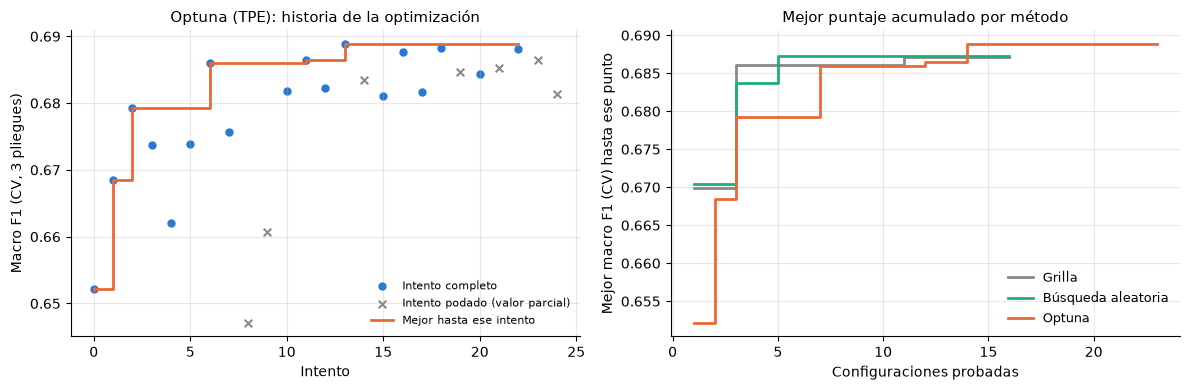

In [22]:
## Historia de la optimización: cada configuración y el mejor puntaje acumulado de cada método
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

ax = axes[0]
ax.scatter(completos["number"], completos["value"], color=AZUL, s=25, label="Intento completo")
podados = intentos[intentos["state"] == "PRUNED"]
## Para los podados mostramos su último valor intermedio (promedio de los pliegues que alcanzó)
val_podados = [estudio.trials[i].intermediate_values[max(estudio.trials[i].intermediate_values)] for i in podados["number"]]
ax.scatter(podados["number"], val_podados, color=GRIS, marker="x", s=30, label="Intento podado (valor parcial)")
ax.plot(completos["number"], completos["value"].cummax(), color=NARANJA, linewidth=2, drawstyle="steps-post",
        label="Mejor hasta ese intento")
ax.set_xlabel("Intento")
ax.set_ylabel("Macro F1 (CV, 3 pliegues)")
ax.set_title("Optuna (TPE): historia de la optimización")
ax.legend(frameon=False, fontsize=8, loc="lower right")

ax = axes[1]
mejor_grilla = np.maximum.accumulate(busqueda_grilla.cv_results_["mean_test_score"])
mejor_azar = np.maximum.accumulate(busqueda_azar.cv_results_["mean_test_score"])
ax.plot(np.arange(1, len(mejor_grilla) + 1), mejor_grilla, color=GRIS,
        linewidth=2, drawstyle="steps-post", label="Grilla")
ax.plot(np.arange(1, len(mejor_azar) + 1), mejor_azar, color=VERDE,
        linewidth=2, drawstyle="steps-post", label="Búsqueda aleatoria")
ax.plot(completos["number"] + 1, completos["value"].cummax(), color=NARANJA, linewidth=2,
        drawstyle="steps-post", label="Optuna")
ax.set_xlabel("Configuraciones probadas")
ax.set_ylabel("Mejor macro F1 (CV) hasta ese punto")
ax.set_title("Mejor puntaje acumulado por método")
ax.legend(frameon=False, fontsize=9)
plt.tight_layout()
plt.show()

**Una sola evaluación en validación.** Elegimos el método cuyo mejor puntaje de validación cruzada es más alto, reajustamos esa configuración con **todo** el entrenamiento y la evaluamos **una vez** en validación.

In [23]:
## Tabla comparativa y evaluación única del ganador en validación
resumen_ajuste = pd.DataFrame([
    {"Método": "Grilla (16 configuraciones)", "Mejor macro F1 (CV)": busqueda_grilla.best_score_,
     "Tiempo (s)": t_grilla, "Parámetros": busqueda_grilla.best_params_},
    {"Método": "Búsqueda aleatoria (16 configuraciones)", "Mejor macro F1 (CV)": busqueda_azar.best_score_,
     "Tiempo (s)": t_azar, "Parámetros": busqueda_azar.best_params_},
    {"Método": "Optuna TPE + poda (25 intentos)", "Mejor macro F1 (CV)": estudio.best_value,
     "Tiempo (s)": t_optuna, "Parámetros": estudio.best_params},
]).set_index("Método")

ganador = resumen_ajuste["Mejor macro F1 (CV)"].idxmax()
modelo_final = HistGradientBoostingClassifier(max_iter=100, early_stopping=False, random_state=86,
                                              **resumen_ajuste.loc[ganador, "Parámetros"])
modelo_final.fit(X_train, y_train_c)
print(f"Ganador por CV: {ganador}")
print(f"Macro F1 en validación (una sola vez): {macro_f1(y_val_c, modelo_final.predict(X_val)):.3f}")
resumen_ajuste.drop(columns="Parámetros").round({"Mejor macro F1 (CV)": 4, "Tiempo (s)": 1})

Ganador por CV: Optuna TPE + poda (25 intentos)
Macro F1 en validación (una sola vez): 0.685


,Mejor macro F1 (CV),Tiempo (s)
Método,,
Grilla (16 configuraciones),0.6872,53.5
Búsqueda aleatoria (16 configuraciones),0.6872,52.0
Optuna TPE + poda (25 intentos),0.6888,79.0


**Para recordar.**
- Con el mismo presupuesto, la búsqueda aleatoria probó 16 valores distintos de cada hiperparámetro y la grilla solo 2. Aun así, aquí la grilla no queda atrás (con scikit-learn 1.9 ambas empatan; con la versión de Colab la grilla gana por unas milésimas): sus valores ya caían en una zona buena. La ventaja de la búsqueda aleatoria aparece cuando solo unos pocos hiperparámetros importan y la grilla gasta intentos en combinaciones de los que no importan (Bergstra y Bengio, 2012); con más hiperparámetros, la grilla además crece de forma exponencial.
- Optuna alcanza el mejor puntaje o queda muy cerca, y la poda detuvo varios intentos tras uno o dos pliegues. Pero la diferencia entre los tres métodos (unas milésimas) es menor que el ruido de la validación cruzada (S9, sección 5): con otra versión de scikit-learn, como la de Colab, el orden entre ellos puede cambiar. Las ventajas de la optimización bayesiana crecen con espacios más grandes y presupuestos más largos.
- En validación, el modelo ajustado queda prácticamente igual que el `HistGradientBoosting` sin ajustar de la sección 5.2 (unas milésimas arriba o abajo, según la versión). Los valores por defecto de los modelos modernos de *boosting* suelen ser buenos; ajustar rinde más en modelos sensibles a sus hiperparámetros (SVM, k-NN, redes neuronales) o con otros datos.
- El mejor puntaje de CV de una búsqueda es **optimista** (se eligió por ser el máximo; S9, sección 5): por eso el número que se informa es el de un conjunto que no participó en la búsqueda.
- Los tiempos dependen del equipo, y la grilla y la búsqueda aleatoria se pueden paralelizar con `n_jobs`. Aquí los tres métodos corren en secuencia para comparar en igualdad de condiciones.

## 8. Datos temporales: ventanas expansivas y móviles

**▶ En vivo.** Cuando el modelo se usará para **predecir el futuro**, la validación debe imitar ese uso: entrenar con el pasado y evaluar con lo que viene después. Hyndman y Athanasopoulos (*Forecasting: Principles and Practice*, 3.ª ed., sección 5.10) llaman a esto **validación cruzada de series de tiempo** o evaluación con **origen de pronóstico móvil** (*rolling forecasting origin*): cada conjunto de evaluación contiene observaciones posteriores a todas las de su conjunto de entrenamiento, de modo que el pronóstico nunca usa información futura.

**Datos.** *Beijing Multi-Site Air-Quality Data* (Chen, 2017; repositorio UCI, DOI 10.24432/C5RK5G; licencia CC BY 4.0; introducido por Zhang et al., 2017): mediciones **horarias** de 6 contaminantes y 6 variables meteorológicas en 12 estaciones de Pekín, entre el 1 de marzo de 2013 y el 28 de febrero de 2017. Usamos una estación, **Dongsi** (centro de la ciudad).
- Es un problema que interesa a ambas cohortes: pronosticar episodios de contaminación sirve para activar alertas sanitarias y restricciones (política pública) y para planificar la operación de industrias y redes (ingeniería).
- La descarga (≈ 8 MB) se lee **en memoria** con la librería estándar (`urllib`, `zipfile`), sin escribir archivos. El ZIP del repositorio contiene otro ZIP con los 12 CSV de las estaciones, además de algunos archivos ajenos al conjunto de datos que no usamos.

In [24]:
## Descargar el ZIP de UCI y leer una estación (todo en memoria; no se escriben archivos)
URL_AIRE = "https://archive.ics.uci.edu/static/public/501/beijing+multi+site+air+quality+data.zip"


def leer_estacion(estacion="Dongsi", url=URL_AIRE, timeout=120):
    with urllib.request.urlopen(url, timeout=timeout) as respuesta:
        externo = zipfile.ZipFile(io.BytesIO(respuesta.read()))
    interno = zipfile.ZipFile(io.BytesIO(externo.read("PRSA2017_Data_20130301-20170228.zip")))
    nombre = f"PRSA_Data_20130301-20170228/PRSA_Data_{estacion}_20130301-20170228.csv"
    return pd.read_csv(io.BytesIO(interno.read(nombre)))


t0 = time.perf_counter()
aire_horario = leer_estacion("Dongsi")
print(f"Descarga y lectura: {time.perf_counter() - t0:.1f} s | {aire_horario.shape[0]:,} horas × {aire_horario.shape[1]} columnas")
print("Proporción de horas sin PM2.5:", round(aire_horario["PM2.5"].isna().mean(), 3))
aire_horario.head(3)

Descarga y lectura: 4.7 s | 35,064 horas × 18 columnas
Proporción de horas sin PM2.5: 0.021


,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station
0,1,2013,3,1,0,9.0,9.0,3.0,17.0,300.0,89.0,-0.5,1024.5,-21.4,0.0,NNW,5.7,Dongsi
1,2,2013,3,1,1,4.0,4.0,3.0,16.0,300.0,88.0,-0.7,1025.1,-22.1,0.0,NW,3.9,Dongsi
2,3,2013,3,1,2,7.0,7.0,NaN,17.0,300.0,60.0,-1.2,1025.3,-24.6,0.0,NNW,5.3,Dongsi


**Agregación diaria y tarea.** Promediamos por día la concentración de PM2.5 (µg/m³), la temperatura (`TEMP`), la presión (`PRES`), el punto de rocío (`DEWP`) y la velocidad del viento (`WSPM`), y sumamos la lluvia (`RAIN`). Los pocos días sin ninguna medición de PM2.5 se interpolan linealmente (a lo sumo 3 días seguidos).

**Tarea (regresión):** predecir el PM2.5 medio del **día siguiente** ($t+1$) con lo que se sabe al cierre del día $t$. Comparamos dos conjuntos de predictores:
- **Modelo A (autorregresivo):** PM2.5 de los días $t, t-1, \dots, t-6$ (7 rezagos) y la meteorología del día $t$.
- **Modelo B (calendario):** la meteorología del día $t$, el **día del año** y un **índice temporal** (días desde el inicio). No usa la contaminación reciente.

**Partición.** Los días cuyo objetivo cae antes del 1 de marzo de 2016 (tres años) forman el entrenamiento, donde se hace toda la validación cruzada. El último año (marzo de 2016 a febrero de 2017) es un **período de reserva** que se usa una sola vez, al final, como "futuro" verdadero. La línea base es el **pronóstico ingenuo** (*naive*): mañana será igual que hoy (Hyndman y Athanasopoulos, sección 5.2).

In [25]:
## Agregación diaria
aire_horario["fecha"] = pd.to_datetime(aire_horario[["year", "month", "day"]])
diario = aire_horario.groupby("fecha").agg(
    PM25=("PM2.5", "mean"), TEMP=("TEMP", "mean"), PRES=("PRES", "mean"),
    DEWP=("DEWP", "mean"), RAIN=("RAIN", "sum"), WSPM=("WSPM", "mean"))
print(f"Días: {len(diario):,} | días sin PM2.5: {diario['PM25'].isna().sum()}")
diario["PM25"] = diario["PM25"].interpolate(limit=3)

## Predictores al cierre del día t y objetivo = PM2.5 del día t+1
datos = pd.DataFrame(index=diario.index)
for k in range(7):
    datos[f"PM25_t-{k}" if k else "PM25_t"] = diario["PM25"].shift(k)
for c in ["TEMP", "PRES", "DEWP", "RAIN", "WSPM"]:
    datos[c] = diario[c]
datos["dia_del_año"] = datos.index.dayofyear
datos["indice_t"] = np.arange(len(datos))
datos["objetivo"] = diario["PM25"].shift(-1)
datos = datos.dropna()

meteo = ["TEMP", "PRES", "DEWP", "RAIN", "WSPM"]
modelo_A = [c for c in datos.columns if c.startswith("PM25")] + meteo
modelo_B = meteo + ["dia_del_año", "indice_t"]

## Entrenamiento: objetivo antes del 1 de marzo de 2016; reserva: el último año
fecha_objetivo = datos.index + pd.Timedelta(days=1)
INICIO_RESERVA = pd.Timestamp("2016-03-01")
entren, reserva = datos[fecha_objetivo < INICIO_RESERVA], datos[fecha_objetivo >= INICIO_RESERVA]
print(f"Entrenamiento: {len(entren)} días ({entren.index.min():%d-%m-%Y} a {entren.index.max():%d-%m-%Y}) | "
      f"reserva: {len(reserva)} días")
print("Modelo A:", modelo_A)
print("Modelo B:", modelo_B)

Días: 1,461 | días sin PM2.5: 5
Entrenamiento: 1089 días (07-03-2013 a 28-02-2016) | reserva: 365 días
Modelo A: ['PM25_t', 'PM25_t-1', 'PM25_t-2', 'PM25_t-3', 'PM25_t-4', 'PM25_t-5', 'PM25_t-6', 'TEMP', 'PRES', 'DEWP', 'RAIN', 'WSPM']
Modelo B: ['TEMP', 'PRES', 'DEWP', 'RAIN', 'WSPM', 'dia_del_año', 'indice_t']


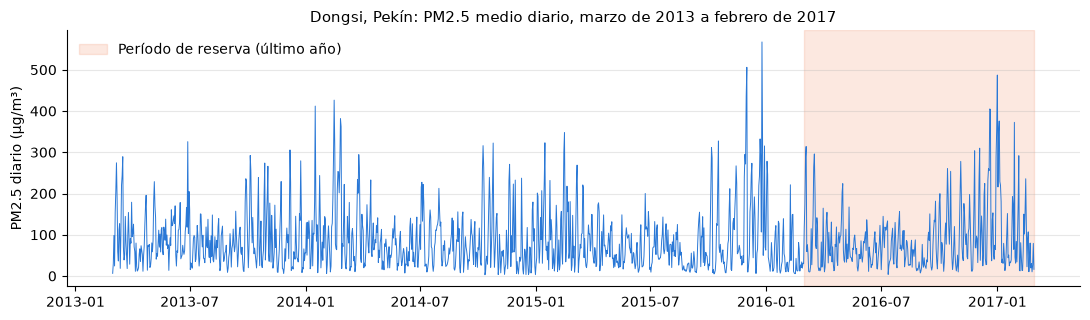

In [26]:
## La serie diaria de PM2.5 y el período de reserva
fig, ax = plt.subplots(figsize=(11, 3.3))
ax.plot(diario.index, diario["PM25"], color=AZUL, linewidth=0.7)
ax.axvspan(INICIO_RESERVA, diario.index.max(), color=NARANJA, alpha=0.15, label="Período de reserva (último año)")
ax.set_ylabel("PM2.5 diario (µg/m³)")
ax.set_title("Dongsi, Pekín: PM2.5 medio diario, marzo de 2013 a febrero de 2017")
ax.legend(frameon=False, loc="upper left")
ax.grid(axis="x")
plt.tight_layout()
plt.show()

### 8.1 Cuatro formas de partir una serie de tiempo

- **(a) `KFold` al azar** (como en S9): mezcla los días; cada pliegue de evaluación queda rodeado de días de entrenamiento anteriores **y posteriores**. El modelo "conoce el futuro".
- **(b) Ventana expansiva** (`TimeSeriesSplit`): cada pliegue entrena con **todo** el pasado disponible y evalúa con el bloque siguiente. Es el esquema de Hyndman y Athanasopoulos (sección 5.10).
- **(c) Ventana móvil** (`TimeSeriesSplit(max_train_size=365)`): entrena solo con los **últimos 365 días**. Conviene si la relación cambia con el tiempo y los datos antiguos dejan de ser representativos.
- **(d) Brecha** (`TimeSeriesSplit(gap=7)`): deja 7 días sin usar entre el entrenamiento y la evaluación. Es necesaria cuando el objetivo abarca varios días (por ejemplo, el promedio de la próxima semana) o cuando los datos llegan con retraso; sin ella, los últimos objetivos de entrenamiento se solaparían con el período evaluado.

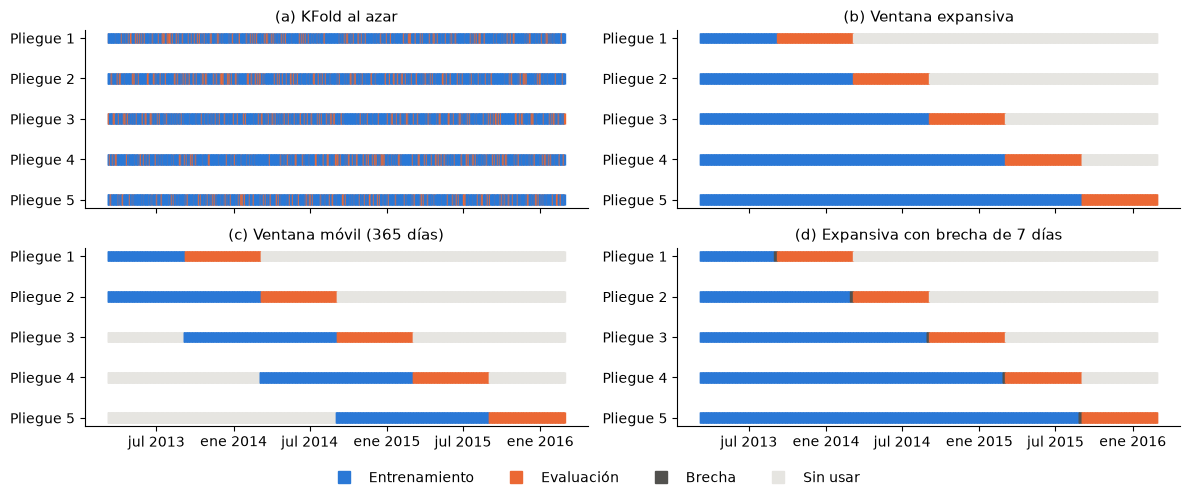

In [27]:
## Diagrama de los pliegues (5 en cada esquema) sobre los días de entrenamiento
esquemas = {
    "(a) KFold al azar": KFold(n_splits=5, shuffle=True, random_state=86),
    "(b) Ventana expansiva": TimeSeriesSplit(n_splits=5),
    "(c) Ventana móvil (365 días)": TimeSeriesSplit(n_splits=5, max_train_size=365),
    "(d) Expansiva con brecha de 7 días": TimeSeriesSplit(n_splits=5, gap=7),
}
fechas = entren.index
fig, axes = plt.subplots(2, 2, figsize=(12, 5), sharex=True)
for ax, (nombre, cv) in zip(axes.ravel(), esquemas.items()):
    for i, (idx_tr, idx_ev) in enumerate(cv.split(entren)):
        estado = np.full(len(fechas), 0)          ## 0 = sin usar
        estado[idx_tr], estado[idx_ev] = 1, 2      ## 1 = entrenamiento, 2 = evaluación
        if "brecha" in nombre:
            estado[idx_tr.max() + 1:idx_ev.min()] = 3   ## 3 = brecha
        colores = np.array(["#e6e5e1", AZUL, NARANJA, "#52514e"])[estado]
        ax.scatter(fechas, np.full(len(fechas), i + 1), c=colores, marker="|", s=60, linewidths=1)
    ax.set_yticks(range(1, 6), [f"Pliegue {i}" for i in range(1, 6)])
    ax.set_xticks(pd.to_datetime(["2013-07-01", "2014-01-01", "2014-07-01", "2015-01-01", "2015-07-01", "2016-01-01"]),
                  ["jul 2013", "ene 2014", "jul 2014", "ene 2015", "jul 2015", "ene 2016"])
    ax.invert_yaxis()
    ax.set_title(nombre)
    ax.grid(False)
manijas = [plt.Line2D([], [], color=c, marker="s", linestyle="", markersize=8) for c in [AZUL, NARANJA, "#52514e", "#e6e5e1"]]
fig.legend(manijas, ["Entrenamiento", "Evaluación", "Brecha", "Sin usar"], loc="lower center", ncol=4, frameon=False)
plt.tight_layout(rect=(0, 0.06, 1, 1))
plt.show()

### 8.2 ¿Cuán optimista es la validación al azar?

Usamos un random forest de regresión (300 árboles, `min_samples_leaf=5`) y el **error absoluto medio** (MAE, en µg/m³; S9, sección 10). Para cada modelo y esquema estimamos el MAE con validación cruzada en el entrenamiento. Luego ajustamos con todo el entrenamiento y medimos el MAE real en el período de reserva, el "futuro" que la validación cruzada intenta anticipar.

In [28]:
## MAE estimado con cada esquema (entrenamiento) y MAE real en el período de reserva
rf_aire = RandomForestRegressor(n_estimators=300, min_samples_leaf=5, n_jobs=N_HILOS, random_state=86)
t0 = time.perf_counter()
filas, por_pliegue = [], {}
for nombre, cv in esquemas.items():
    fila = {"Esquema": nombre}
    for etiqueta, cols in [("Modelo A", modelo_A), ("Modelo B", modelo_B)]:
        res = cross_validate(rf_aire, entren[cols], entren["objetivo"], cv=cv, scoring="neg_mean_absolute_error")
        fila[f"MAE {etiqueta}"] = -res["test_score"].mean()
        por_pliegue[(nombre, etiqueta)] = -res["test_score"]
    filas.append(fila)

fila_reserva = {"Esquema": "Período de reserva (MAE real, último año)"}
for etiqueta, cols in [("Modelo A", modelo_A), ("Modelo B", modelo_B)]:
    rf_aire.fit(entren[cols], entren["objetivo"])
    fila_reserva[f"MAE {etiqueta}"] = mean_absolute_error(reserva["objetivo"], rf_aire.predict(reserva[cols]))
filas.append(fila_reserva)
print(f"Tiempo: {time.perf_counter() - t0:.1f} s")

tabla_tiempo = pd.DataFrame(filas).set_index("Esquema")
tabla_tiempo["B − A"] = tabla_tiempo["MAE Modelo B"] - tabla_tiempo["MAE Modelo A"]
print(f"Línea base ingenua (mañana = hoy), MAE en la reserva: "
      f"{mean_absolute_error(reserva['objetivo'], reserva['PM25_t']):.1f} µg/m³")
tabla_tiempo.round(1)

Tiempo: 13.4 s
Línea base ingenua (mañana = hoy), MAE en la reserva: 48.3 µg/m³


,MAE Modelo A,MAE Modelo B,B − A
Esquema,,,
(a) KFold al azar,41.9,43.9,2.0
(b) Ventana expansiva,45.6,53.1,7.5
(c) Ventana móvil (365 días),45.9,53.8,7.9
(d) Expansiva con brecha de 7 días,45.6,58.4,12.9
"Período de reserva (MAE real, último año)",41.1,48.9,7.8


In [29]:
## Ventana expansiva vs móvil, pliegue a pliegue (Modelo A)
pd.DataFrame({
    "Expansiva: días de entrenamiento": [len(tr) for tr, _ in esquemas["(b) Ventana expansiva"].split(entren)],
    "MAE expansiva": por_pliegue[("(b) Ventana expansiva", "Modelo A")],
    "Móvil: días de entrenamiento": [len(tr) for tr, _ in esquemas["(c) Ventana móvil (365 días)"].split(entren)],
    "MAE móvil": por_pliegue[("(c) Ventana móvil (365 días)", "Modelo A")],
}, index=[f"Pliegue {i}" for i in range(1, 6)]).round(1)

,Expansiva: días de entrenamiento,MAE expansiva,Móvil: días de entrenamiento,MAE móvil
Pliegue 1,184,57.9,184,57.9
Pliegue 2,365,33.9,365,33.9
Pliegue 3,546,50.1,365,50.8
Pliegue 4,727,32.1,365,32.0
Pliegue 5,908,54.1,365,54.8


**Para recordar.**
- **El problema no es solo el nivel, sino el orden.** Con `KFold` al azar, los modelos A y B parecen casi equivalentes. En el período de reserva, el modelo B es mucho peor que el A, e incluso algo peor que la línea base ingenua. Las ventanas temporales sí anticipan esa diferencia; la validación al azar la esconde.
- ¿Por qué? Con pliegues al azar, cada día evaluado tiene en el entrenamiento el día anterior **y el siguiente**, y los episodios de contaminación duran varios días. El índice temporal le permite al bosque reconocer a esos vecinos e **interpolar** entre ellos, algo imposible al pronosticar el futuro. Es una fuga de información del futuro, como las de S9.
- Para el modelo A, la validación al azar no es muy optimista: los 7 rezagos ya capturan la dependencia entre días. Bergmeir, Hyndman y Koo (2018) muestran que, en modelos autorregresivos puros con errores no correlacionados, la validación cruzada estándar es válida. En la práctica no sabemos si los predictores capturan toda la dependencia, y la validación temporal es la opción segura.
- Las estimaciones temporales quedan algo por encima del MAE real de la reserva. Cada pliegue cubre unos seis meses, y los que incluyen el invierno (más contaminado y más variable) tienen errores mucho mayores que los de verano. Además, el primer pliegue entrena con solo 184 días. Con pocos pliegues largos, la estimación depende de qué estaciones del año caen en cada uno.
- Aquí la ventana **móvil** de 365 días rinde casi igual que la expansiva: tres años de datos no muestran un cambio fuerte en la relación entre predictores y objetivo. La ventana móvil usa menos datos, pero se adapta si esa relación cambia (por ejemplo, tras una nueva normativa de emisiones). El tamaño de la ventana es una decisión de diseño que también se valida (ejercicio c).
- La brecha no cambia el resultado del modelo A, pero empeora todavía más el del modelo B: alejar 7 días el entrenamiento del período evaluado le quita justo lo que explotaba, la cercanía en el tiempo. En general, la brecha es necesaria cuando el objetivo abarca varios días o cuando los datos llegan con retraso (ejercicio c).

## 9. Ejercicios

### (a) Un ensamble con a lo sumo 5 predictores

En el desafío de predicción se permiten ensambles, pero el límite de **5 predictores** se aplica a la **unión** de las variables de origen que usan **todos** sus componentes. Un ensamble cuyo random forest usa 3 predictores y cuyo XGBoost usa otros 3 distintos usa 6 y **no cumple**. La función de abajo verifica la regla.

**Tareas.**
1. Construya un ensamble (votación blanda, *stacking* o un promedio de probabilidades) sobre *California Housing* con a lo sumo 5 predictores en total. Puede partir de la selección hacia adelante del ejercicio (a) de S8.
2. Compare su macro F1 en validación con el del mejor modelo individual con los mismos 5 predictores. ¿Ganó algo el ensamble?
3. Elija los hiperparámetros y los pesos con validación cruzada en entrenamiento, no mirando validación.

In [30]:
## Verificar la regla de los 5 predictores: cuenta la UNIÓN de las variables de todos los componentes
def predictores_del_ensamble(*listas, limite=5):
    union = sorted(set().union(*listas))
    print(f"{len(union)} predictores: {union} → {'cumple' if len(union) <= limite else 'NO cumple'} el límite de {limite}")
    return union


_ = predictores_del_ensamble(["MedInc", "Latitude", "Longitude"], ["MedInc", "AveOccup", "Latitude"])
_ = predictores_del_ensamble(["MedInc", "Latitude", "Longitude"], ["MedInc", "AveOccup", "HouseAge", "Population"])

4 predictores: ['AveOccup', 'Latitude', 'Longitude', 'MedInc'] → cumple el límite de 5
6 predictores: ['AveOccup', 'HouseAge', 'Latitude', 'Longitude', 'MedInc', 'Population'] → NO cumple el límite de 5


In [31]:
## Plantilla para el ejercicio (a): descomente y complete
# cols = predictores_del_ensamble([...], [...])
# ensamble = VotingClassifier([
#     ("rf", RandomForestClassifier(n_estimators=300, n_jobs=N_HILOS, random_state=86)),
#     ("hgb", HistGradientBoostingClassifier(random_state=86)),
# ], voting="soft")
# ensamble.fit(X_train[cols], y_train_c)
# print(macro_f1(y_val_c, ensamble.predict(X_val[cols])))

### (b) Optuna contra la búsqueda aleatoria con un presupuesto fijo

1. Ajuste un random forest o XGBoost con Optuna y con `RandomizedSearchCV`, ambos con **el mismo número de configuraciones** (por ejemplo, 30) y los mismos pliegues. Defina el espacio de búsqueda (por ejemplo, `max_features`, `min_samples_leaf`, `max_depth`).
2. Compare el mejor puntaje de CV, el tiempo y la curva del mejor puntaje acumulado (como en la sección 7.1).
3. Repita con otra semilla (`TPESampler(seed=...)` y `random_state=...`). ¿Se mantiene la diferencia entre métodos? ¿Qué dice esto sobre el ruido de la validación cruzada?

In [32]:
## Plantilla para el ejercicio (b): descomente y complete
# def objetivo_rf(trial):
#     modelo = RandomForestClassifier(
#         n_estimators=200, n_jobs=N_HILOS, random_state=86,
#         max_features=trial.suggest_int("max_features", 1, 8),
#         min_samples_leaf=trial.suggest_int("min_samples_leaf", 1, 50),
#     )
#     return cross_validate(modelo, X_train, y_train_c, cv=cv3, scoring="f1_macro")["test_score"].mean()
#
# estudio_rf = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=86))
# estudio_rf.optimize(objetivo_rf, n_trials=30)
# azar_rf = RandomizedSearchCV(RandomForestClassifier(n_estimators=200, n_jobs=N_HILOS, random_state=86),
#                              {"max_features": randint(1, 9), "min_samples_leaf": randint(1, 51)},
#                              n_iter=30, cv=cv3, scoring="f1_macro", random_state=86).fit(X_train, y_train_c)
# print(estudio_rf.best_value, azar_rf.best_score_)

### (c) El tamaño de la ventana en la serie de calidad del aire

1. Con el modelo A de la sección 8, compare ventanas móviles de 90, 180, 365 y 730 días con la ventana expansiva (`max_train_size=None`). Use los mismos 5 pliegues de evaluación (mismo `test_size`).
2. ¿Qué tamaño minimiza el MAE? ¿Coincide con el que rinde mejor en el período de reserva?
3. Pruebe un objetivo a 7 días (el PM2.5 medio de los próximos 7 días) y compare `gap=0` con `gap=7`. ¿Cuándo importa la brecha?
4. Discusión: un organismo que emite alertas sanitarias, ¿preferiría una ventana corta o una larga? ¿Y si cambia la normativa de emisiones?

In [33]:
## Plantilla para el ejercicio (c): descomente y complete
# for ventana in [90, 180, 365, 730, None]:
#     cv = TimeSeriesSplit(n_splits=5, max_train_size=ventana, test_size=150)
#     mae = -cross_validate(rf_aire, entren[modelo_A], entren["objetivo"], cv=cv,
#                           scoring="neg_mean_absolute_error")["test_score"]
#     print(ventana, mae.mean().round(1), mae.round(1))

**Para recordar (síntesis de la sesión).**
- Un ensamble mejora cuando sus miembros son **buenos y distintos**. El *bagging* y el random forest reducen la varianza; el *boosting*, sobre todo el sesgo.
- La votación blanda requiere probabilidades comparables (calibradas). El *stacking* requiere predicciones **fuera de la muestra** para el meta-aprendiz.
- La parada temprana y el ajuste de hiperparámetros son parte del entrenamiento: se hacen con datos de entrenamiento (porción interna o validación cruzada), nunca con los datos con que se informa el resultado.
- Búsqueda aleatoria antes que grilla; optimización bayesiana (Optuna) cuando el presupuesto o el espacio crecen.
- Si el modelo pronosticará el futuro, la validación debe respetar el orden temporal: ventanas expansivas o móviles, con brecha cuando el horizonte lo exige.
- **Próxima sesión (S11):** lanzamiento del desafío de predicción.

**Referencias**
- Akiba, T., Sano, S., Yanase, T., Ohta, T. y Koyama, M. (2019). Optuna: A next-generation hyperparameter optimization framework. *Proceedings of the 25th ACM SIGKDD International Conference on Knowledge Discovery & Data Mining*, 2623–2631.
- Bergmeir, C., Hyndman, R. J. y Koo, B. (2018). A note on the validity of cross-validation for evaluating autoregressive time series prediction. *Computational Statistics & Data Analysis*, 120, 70–83.
- Bergstra, J. y Bengio, Y. (2012). Random search for hyper-parameter optimization. *Journal of Machine Learning Research*, 13, 281–305.
- Breiman, L. (1996). Bagging predictors. *Machine Learning*, 24(2), 123–140.
- Breiman, L. (2001). Random forests. *Machine Learning*, 45(1), 5–32.
- Chen, S. (2017). *Beijing Multi-Site Air Quality* [conjunto de datos]. UCI Machine Learning Repository. https://doi.org/10.24432/C5RK5G
- Chen, T. y Guestrin, C. (2016). XGBoost: A scalable tree boosting system. *Proceedings of the 22nd ACM SIGKDD International Conference on Knowledge Discovery and Data Mining*, 785–794.
- Freund, Y. y Schapire, R. E. (1997). A decision-theoretic generalization of on-line learning and an application to boosting. *Journal of Computer and System Sciences*, 55(1), 119–139.
- Friedman, J. H. (2001). Greedy function approximation: A gradient boosting machine. *The Annals of Statistics*, 29(5), 1189–1232.
- Grinsztajn, L., Oyallon, E. y Varoquaux, G. (2022). Why do tree-based models still outperform deep learning on typical tabular data? *Advances in Neural Information Processing Systems*, 35, 507–520.
- Hastie, T., Tibshirani, R. y Friedman, J. (2009). *The Elements of Statistical Learning* (2.ª ed.). Springer. Secciones 8.8 y 15.2.
- Hyndman, R. J. y Athanasopoulos, G. (2021). *Forecasting: Principles and Practice* (3.ª ed.). OTexts. https://otexts.com/fpp3/ (secciones 5.2 y 5.10).
- Pace, R. K. y Barry, R. (1997). Sparse spatial autoregressions. *Statistics & Probability Letters*, 33(3), 291–297.
- Tan, P.-N., Steinbach, M. y Kumar, V. (2006). *Introduction to Data Mining* (1.ª ed.). Pearson Addison-Wesley. Sección 5.6.
- Wolpert, D. H. (1992). Stacked generalization. *Neural Networks*, 5(2), 241–259.
- Zhang, S., Guo, B., Dong, A., He, J., Xu, Z. y Chen, S. X. (2017). Cautionary tales on air-quality improvement in Beijing. *Proceedings of the Royal Society A*, 473(2205), 20170457.